In [1]:
from neuromodes import mbm as mbm
from neuromodes.io import fetch_example_surf

In [2]:
from scipy.io import loadmat

In [3]:
from importlib.resources import files, as_file
from nsbutils.plotting import plot_surf
from neuromodes import EigenSolver
from neuromodes.io import fetch_example_surf

In [4]:


# Load cortical surface mesh
surf, medmask = fetch_example_surf()

# Initialise solver with surface
solver = EigenSolver(surf, mask=medmask).solve(100)

print(solver)


EigenSolver
-----------
Surface mesh: 29696 vertices (2796 others masked out), 59147 triangles
Mass matrix: consistent
Stiffness matrix: homogeneous
Eigenmodes and eigenvalues: 100 computed


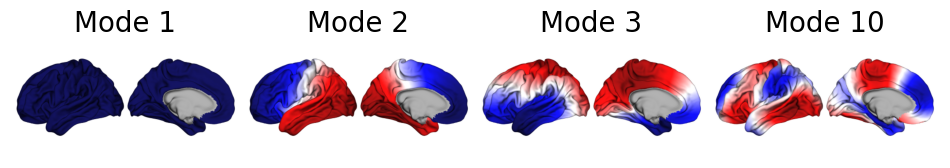

In [5]:
modes_unmasked = solver.unmask_data(solver.emodes)

lh_surfpath = files('neuromodes.data') / 'sp-human_tpl-fsLR_den-32k_hemi-L_midthickness.surf.gii'
with as_file(lh_surfpath) as lh_surfpath:
    plot_surf(lh_surfpath, modes_unmasked[:,[0,1,2,9]], labels=['Mode 1', 'Mode 2', 'Mode 3', 'Mode 10'], cmap='seismic')

In [6]:
face = loadmat('S255_tfMRI_raw_lh_motor_lf.mat')['maps'][medmask]
hand = loadmat('S255_tfMRI_raw_lh_motor_lh.mat')['maps'][medmask]

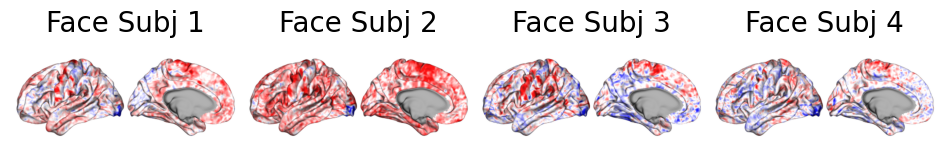

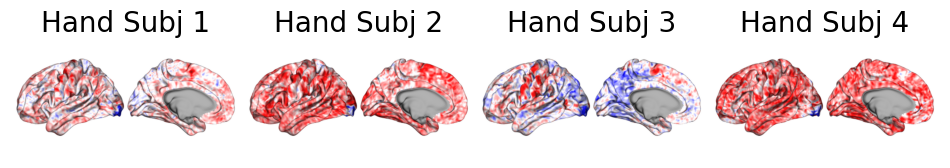

In [7]:
with as_file(lh_surfpath) as lh_surfpath:
    plot_surf(lh_surfpath, solver.unmask_data(face[:,:4]), cmap='seismic', 
              labels = [f'Face Subj {i+1}' for i in range(4)])
    plot_surf(lh_surfpath, solver.unmask_data(hand[:,:4]), cmap='seismic', 
              labels = [f'Hand Subj {i+1}' for i in range(4)])

In [8]:
import numpy as np

nsubj = 255

z = np.zeros((nsubj,1))
o = np.ones((nsubj,1))
design = np.vstack((np.hstack((o, z, np.eye(nsubj))), np.hstack((z, o, np.eye(nsubj)))))
response = np.vstack((face.T, hand.T))
contrast = np.hstack((np.array([[1,-1]]), np.zeros((1,nsubj))))
statTest = 'ttest'

# print(contrast)


In [9]:
t_vertex = mbm.mbm_generate_stat_maps(design, response, contrast, statTest)

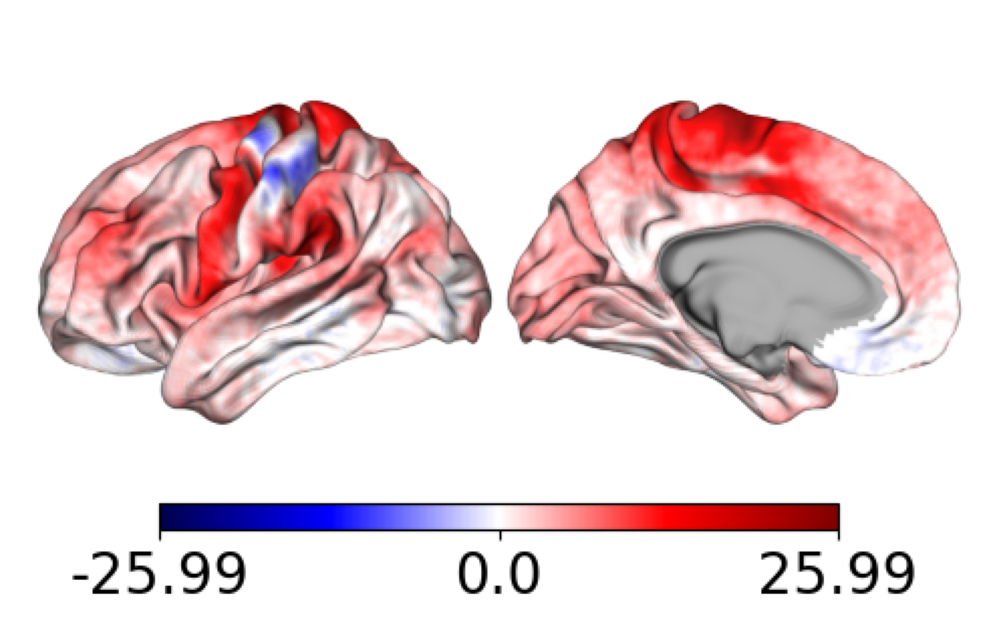

In [10]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(1, 1, figsize=(16, 8))
with as_file(lh_surfpath) as lh_surfpath:
    plot_surf(lh_surfpath, solver.unmask_data(t_vertex), cmap='seismic', center=0, cbar=True, ax=axs)

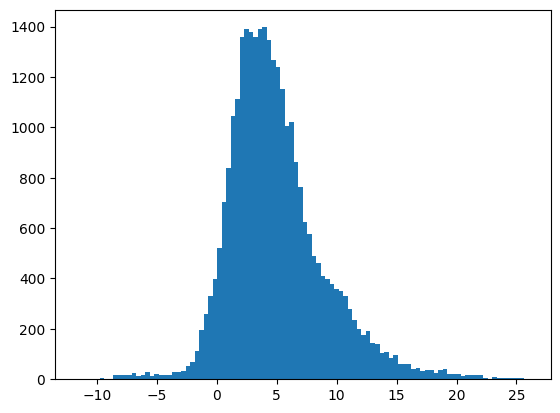

In [11]:
plt.hist(t_vertex, bins=100)
plt.show()

In [12]:
t_vertex_nulls = mbm.mbm_generate_stat_maps(design, response, contrast, statTest, 
                                            n_permutations=10, permutationMethod='shuffle_rows')

In [13]:
p_vertex = mbm.mbm_calc_p_vals(t_vertex, t_vertex_nulls, 'two-sided', None)

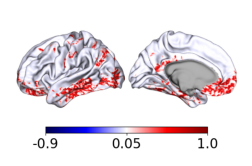

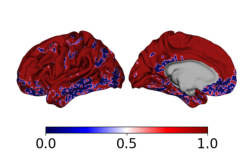

In [14]:
with as_file(lh_surfpath) as lh_surfpath:
    plot_surf(lh_surfpath, solver.unmask_data(p_vertex), cmap='seismic', cbar=True, center = 0.05)
    plot_surf(lh_surfpath, solver.unmask_data(p_vertex<0.05), cmap='seismic', cbar=True, color_range=[0.00, 1.00])

In [15]:
face_mode = solver.decompose(face)
hand_mode = solver.decompose(hand)

response_mode = np.hstack((face_mode, hand_mode)).T


In [16]:
t_modes = mbm.mbm_generate_stat_maps(design, response_mode, contrast, statTest)

In [17]:
t_mode_nulls = mbm.mbm_generate_stat_maps(design, response_mode, contrast, statTest, 
                                           n_permutations=10, permutationMethod='shuffle_rows')

In [18]:
p_modes = mbm.mbm_calc_p_vals(t_modes, t_mode_nulls, 'two-sided', None)


In [30]:
sig_beta = np.mean(face_mode - hand_mode, axis=1) * (p_modes < 0.05)
sig_recon = solver.emodes @ sig_beta[:,None]
print(sig_beta.shape)

(100,)


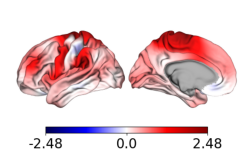

In [31]:
with as_file(lh_surfpath) as lh_surfpath:
    plot_surf(lh_surfpath, solver.unmask_data(sig_recon), cmap='seismic', cbar=True, center = 0.00)